# Modelado Predictivo: Clasificación con Gradient Boosting
**Proyecto:** Clasificador de Salud Fetal (Dataset Cardiotocography - UCI)

**Contexto:** Este notebook implementa y evalúa un clasificador **Gradient Boosting Multiclase** construido desde cero con ayuda del curso 'Machine_Learning_desde_Cero-11' del Prof. Zucco. 

A diferencia de Random Forest (que entrena árboles profundos e independientes en paralelo mediante *Bagging*), Gradient Boosting construye un ensamble **secuencial y aditivo** de árboles de regresión débiles (`RegressionTree` de poca profundidad). Cada nuevo conjunto de árboles aprende a predecir y corregir los **pseudo-residuos de probabilidad** (el gradiente negativo de la función de pérdida de entropía cruzada multiclase con activación *Softmax*) dejados por las iteraciones anteriores.

### Objetivos del Modelado

1. **Entrenamiento Secuencial Aditivo:** Entrenar un modelo `GradientBoostingClassifier` optimizando la tasa de aprendizaje (`learning_rate`), el número de etapas de boosting (`n_estimators`) y la profundidad de los árboles base (`max_depth`).

2. **Análisis de Evolución por Etapas (`staged_predict`):** Evaluar cómo evoluciona la exactitud y el Macro F1-Score a medida que se agregan árboles al ensamble, verificando la convergencia y descartando sobreajuste (*overfitting*).

3. **Evaluación Clínica Comparativa:** Medir el desempeño por clase mediante la Matriz de Confusión, Recall y F1-Score bajo la misma partición de datos (`seed=42`) utilizada en Random Forest para realizar una comparativa directa y justa.

In [1]:
# Importación de librerías 

import os # Gestión de Carpetas
import sys # Config del sistema
import numpy as np # Matemáticas
import pandas as pd # Tablas
import matplotlib.pyplot as plt # Grafico

# Modificación para importar los módulos fuera de la carpeta actual

root_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
if root_dir not in sys.path:
    sys.path.append(root_dir)

# Importamos el clasificador Gradient Boosting y nuestras utilidades

from src.GradientBoosting import GradientBoostingClassifier
from src.utils_and_metrics import train_test_split, accuracy, confusion_matrix, precision, recall, f1_score

In [2]:
# Carga directa de matrices X & y generadas en 02_EDA_Visualizacion
X_df = pd.read_csv('../data/processed/X_features.csv')
y_df = pd.read_csv('../data/processed/y_target.csv')

X = X_df.to_numpy()
y = y_df['NSP'].to_numpy().ravel().astype(int)

# Partición de datos (80% entrenamiento, 20% prueba) con seed=42 para comparación directa con Random Forest
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, seed=42)

# Visualización de control
display(X_df.head())
print(f"Dimensión de Matriz X (Características): {X.shape}")
print(f"Dimensión de Vector y (Objetivo NSP):    {y.shape}")
print(f"Entrenamiento: X_train={X_train.shape}, y_train={y_train.shape}")
print(f"Prueba:        X_test={X_test.shape}, y_test={y_test.shape}")
print(f"Clases en y:   {np.unique(y)}")

,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,ALTV,...,Width,Min,Max,Nmax,Nzeros,Mode,Mean,Median,Variance,Tendency
0,120.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,73.0,0.5,43.0,...,64.0,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0
1,132.0,0.006380,0.0,0.006380,0.003190,0.0,0.0,17.0,2.1,0.0,...,130.0,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0
2,133.0,0.003322,0.0,0.008306,0.003322,0.0,0.0,16.0,2.1,0.0,...,130.0,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0
3,134.0,0.002561,0.0,0.007682,0.002561,0.0,0.0,16.0,2.4,0.0,...,117.0,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0
4,132.0,0.006515,0.0,0.008143,0.000000,0.0,0.0,16.0,2.4,0.0,...,117.0,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0


Dimensión de Matriz X (Características): (2126, 21)
Dimensión de Vector y (Objetivo NSP):    (2126,)
Entrenamiento: X_train=(1700, 21), y_train=(1700,)
Prueba:        X_test=(426, 21), y_test=(426,)
Clases en y:   [1 2 3]


#### **Entrenamiento de ( GradientBoostingClassifier )**

In [12]:
# Configuración de hiperparámetros del modelo
n_estimators = 100   # Número de etapas secuenciales de boosting
learning_rate = 0.1  # Tasa de aprendizaje (shrinkage)
max_depth = 3        # Árboles cortos para evitar sobreajuste

gb_model = GradientBoostingClassifier(
    n_estimators=n_estimators,
    learning_rate=learning_rate,
    max_depth=max_depth
)

gb_model.fit(X_train, y_train)

# Evaluación sobre el conjunto de entrenamiento
train_preds = gb_model.predict(X_train)
train_accuracy = accuracy(y_train, train_preds)

print("\n--Resultados de Rendimiento en Entrenamiento--")
print(f"Etapas entrenadas (n_estimators):   {len(gb_model.trees_)} etapas ({len(gb_model.trees_) * gb_model.n_classes_} árboles en total)")
print(f"Exactitud Global en Entrenamiento:  {train_accuracy * 100:.2f}%")


--Resultados de Rendimiento en Entrenamiento--
Etapas entrenadas (n_estimators):   100 etapas (300 árboles en total)
Exactitud Global en Entrenamiento:  96.18%


#### **Prueba y Evolución por Etapas ( staged_predict )**

In [13]:
# Predicción final sobre el conjunto de prueba
test_preds = gb_model.predict(X_test)
test_accuracy = accuracy(y_test, test_preds)

# Ajuste de etiquetas (1, 2, 3 -> 0, 1, 2) para indexar la matriz de confusión
clases_unicas = np.unique(y_test)
y_real_test = (y_test - clases_unicas[0]).astype(int)
y_pred_test = (test_preds - clases_unicas[0]).astype(int)
n_classes = gb_model.n_classes_

# Cálculo de matriz y métricas por clase
matriz = confusion_matrix(y_real_test, y_pred_test, n_classes)
precisions = precision(matriz)
recalls = recall(matriz)
f1s = f1_score(matriz)

print("\n--Resultado de Rendimiento en Prueba--")
print(f"Exactitud Global en Prueba:  {test_accuracy * 100:.2f}%")

print("\n--Métricas detalladas por Clase--")
nombres_clases = ["1 (Normal)", "2 (Sospechoso)", "3 (Patológico)"]
for i, nombre in enumerate(nombres_clases):
    print(f"Clase {nombre:14s} -> Precision: {precisions[i]*100:.2f}% | Recall: {recalls[i]*100:.2f}% | F1-Score: {f1s[i]*100:.2f}%")

print(f"\nPromedio Macro F1-Score: {np.mean(f1s)*100:.2f}%")
print("\nMatriz de Confusión (Filas: Real | Columnas: Predicho):")
print(matriz)


--Resultado de Rendimiento en Prueba--
Exactitud Global en Prueba:  93.43%

--Métricas detalladas por Clase--
Clase 1 (Normal)     -> Precision: 94.03% | Recall: 98.81% | F1-Score: 96.36%
Clase 2 (Sospechoso) -> Precision: 90.57% | Recall: 73.85% | F1-Score: 81.36%
Clase 3 (Patológico) -> Precision: 90.48% | Recall: 73.08% | F1-Score: 80.85%

Promedio Macro F1-Score: 86.19%

Matriz de Confusión (Filas: Real | Columnas: Predicho):
[[331   3   1]
 [ 16  48   1]
 [  5   2  19]]


¿Coincide última etapa con predict?: True


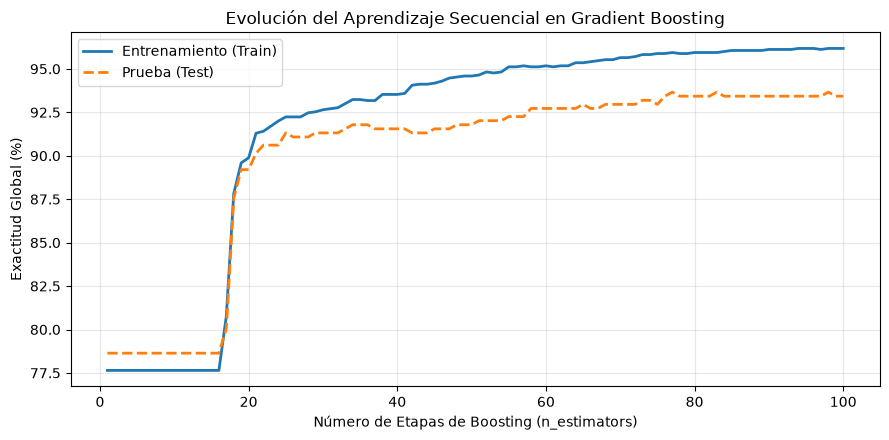

In [ ]:
# Auditoría de convergencia por etapa usando staged_predict
train_stages = gb_model.staged_predict(X_train)
test_stages = gb_model.staged_predict(X_test)

train_acc_curve = [accuracy(y_train, p) * 100 for p in train_stages]
test_acc_curve = [accuracy(y_test, p) * 100 for p in test_stages]

# Gráfica de evolución
plt.figure(figsize=(9, 4.5))
plt.plot(range(1, n_estimators + 1), train_acc_curve, label='Entrenamiento (Train)', linewidth=2)
plt.plot(range(1, n_estimators + 1), test_acc_curve, label='Prueba (Test)', linewidth=2, linestyle='--')
plt.xlabel('Número de Etapas de Boosting (n_estimators)')
plt.ylabel('Exactitud Global (%)')
plt.title('Evolución del Aprendizaje Secuencial en Gradient Boosting')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### Análisis y Conclusiones Finales del Modelo (Gradient Boosting vs. Random Forest)

Al entrenar y probar nuestro modelo de **Gradient Boosting Multiclass**, pudimos ver en la práctica cómo cambia el comportamiento de un algoritmo cuando trabaja con datos desbalanceados sin hacer un muestreo previo. Al revisar la gráfica de evolución por etapas (`staged_predict`), notamos algo muy interesante: durante las primeras ≈ 16 iteraciones, la exactitud se quedó estancada alrededor del ≈ 78%. Esto pasó porque el modelo arranca calculando la proporción real de las clases en el dataset, donde el 77.85% de los registros son fetos con la clasificación ´Normales´. Fue hasta la etapa ≈ 17 cuando la suma de los árboles logró compensar ese peso inicial, haciendo que la exactitud diera un salto hasta estabilizarse alrededor del 93% (≈ 96% en entrenamiento y ≈ 93% en prueba), demostrando que el modelo aprendió bien y no sufrió de sobreajuste (*overfitting*) gracias a usar árboles cortos (`max_depth=3`) y una tasa de aprendizaje de `0.1`.

Ya en la evaluación con los datos de prueba, el Gradient Boosting alcanzó una **Exactitud Global de 93.43%**, superando el 92.72% que habíamos logrado con el Random Forest. Sin embargo, al revisar la matriz de confusión y las métricas por cada clase, nos dimos cuenta de que **tener mayor exactitud general no significa que sea mejor para un hospital**. Como esta versión de Gradient Boosting entrenó con los datos crudos (a diferencia del *Bootstrap* balanceado que programamos en Random Forest), el modelo se volvió muy conservador y se inclinó por predecir la clase mayoritaria (los fetos Normales): acertó 331 de los 335 bebés sanos, logrando un Recall de 98.81% y un F1-Score de 96.36% en la Clase 1 (Normal).

El problema de ser tan conservador con los sanos es que perdió sensibilidad para detectar a los bebés en riesgo (Clase Patologica y Sospechoso). En la Clase 2 (Sospechoso), el Recall bajó a 73.85% (con un F1-Score de 81.36%), y en la Clase 3 (Patológico) el Recall fue de 73.08% (con un F1-Score de 80.85%), dejando el Promedio Macro F1-Score en **86.19%**. Viendo la matriz de confusión, de los 26 casos Patológicos reales, el modelo detectó 19, marcó 2 como sospechosos y dejó escapar 5 como si estuvieran normales. Eso sí, algo muy rescatable es que su **Precisión** en la clase Patológica fue del **90.48%**: de las 21 veces que el modelo lanzó una alerta grave, 19 fueron emergencias reales.

En conclusión, comparar ambos modelos nos dejo claro como elegir una herramienta según lo que se necesite en medicina especialmente. Para un primer filtro de emergencia donde lo más importante es que no se escape ningún bebé con riesgo de hipoxia, nuestro **Random Forest con - Bootstrap balanceado -** sigue siendo la mejor opción porque detecta más casos críticos (84.62% de Recall frente al 73.08% del Gradient Boosting aqui realizado). Por otro lado, el **Gradient Boosting** funciona mejor como un modelo de confirmación: casi no da falsas alarmas y, cuando marca un caso como patológico, tiene más del 90% de certeza de estar en lo correcto.